# Fine-Tuned ResNet-18 on HAM10000: Comprehensive Evaluation
### Diagnostic Performance | Computational Efficiency | Environmental Footprint

This notebook presents a comprehensive, multi-dimensional evaluation of the fine-tuned **ResNet-18** model on the **HAM10000** skin lesion dataset.

The evaluation benchmarks the model across:
1. **Performance**: Accuracy, Precision, Recall, Specificity (OvR), F1-Score, and AUC-ROC (OvR) across all 7 imbalanced classes, with confusion matrices and per-class ROC curves.
2. **Computational Efficiency**: Model parameter count, checkpoint file size, FLOPs (via `ptflops`), inference latency (ms/image with warmup), throughput (images/sec), and peak memory footprint.
3. **Environmental Footprint**: Real-world energy consumption (kWh) and carbon emissions (kg CO₂e) tracked via **CodeCarbon** during test-set inference.


In [1]:
# 1. Environment & Library Setup
import sys
import os
import time
import json
from pathlib import Path

# Add src to system path to reuse existing repo code
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from torch.utils.data import DataLoader, Subset

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.preprocessing import label_binarize

from ham10000.data import Ham10000Dataset
from ham10000.models import build_model
from ptflops import get_model_complexity_info
from codecarbon import EmissionsTracker

# Set plotting style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# Configuration
SEED = 42
IMAGE_SIZE = 224
NUM_CLASSES = 7
CHECKPOINT_PATH = "best_model.pth"
DATA_DIR = "../dataset"
METADATA_CSV = os.path.join(DATA_DIR, "HAM10000_metadata")

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f"Active Device: {device}")
print(f"PyTorch Version: {torch.__version__}")


Active Device: cuda
PyTorch Version: 2.12.0+cu126


In [2]:
# 2. Plot styling shared by the metric-family figures
from matplotlib.patches import FancyBboxPatch
from matplotlib.colors import LinearSegmentedColormap

SURFACE = "#fcfcfb"
TILE = "#ffffff"
INK = "#0b0b0b"
INK_2 = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834"]  # categorical slots 1-2 (blue, orange), validated colourblind-safe
SEQ_CMAP = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)

FAMILY_RC = {
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
    "text.color": INK, "axes.grid": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 9.5,
}

def style_axes(ax, grid_axis="y"):
    """Recessive solid hairline grid behind the marks."""
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8, linestyle="-")
    ax.set_axisbelow(True)
    ax.tick_params(length=0)

def stat_tile(ax, value, label, note=None):
    """A single headline number: when the metric is one value, the number is the chart."""
    ax.axis("off")
    ax.add_patch(FancyBboxPatch(
        (0.02, 0.06), 0.96, 0.88, transform=ax.transAxes,
        boxstyle="round,pad=0,rounding_size=0.05", facecolor=TILE, edgecolor=GRID, linewidth=1,
    ))
    ax.text(0.08, 0.72, label, transform=ax.transAxes, fontsize=10.5, color=INK_2, va="center")
    ax.text(0.08, 0.44, value, transform=ax.transAxes, fontsize=19, color=INK, fontweight="semibold", va="center")
    if note:
        ax.text(0.08, 0.19, note, transform=ax.transAxes, fontsize=9, color=MUTED, va="center")

In [3]:
# 3. Dataset Preparation (Lesion-Wise 80/10/10 Split)
# Deterministic validation/test transform: resize to 224x224 and normalize using ImageNet statistics
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Load dataset
full_dataset = Ham10000Dataset(METADATA_CSV, DATA_DIR, transform=eval_transform)
class_to_idx = full_dataset.class_to_idx
idx_to_class = {v: k for k, v in class_to_idx.items()}
class_names = [idx_to_class[i] for i in range(NUM_CLASSES)]

# Lesion-wise split to prevent data leakage across images of the same lesion
lesion_ids = full_dataset.data["lesion_id"].unique()

# Step 1: 80% train vs 20% holdout (exact same split as training)
train_ids, holdout_ids = train_test_split(lesion_ids, train_size=0.8, random_state=SEED)

# Step 2: Split 20% holdout into 10% validation (checkpoint selection) and 10% test (never seen in training)
val_ids, test_ids = train_test_split(holdout_ids, test_size=0.5, random_state=SEED)

test_mask = full_dataset.data["lesion_id"].isin(test_ids)
test_indices = full_dataset.data.index[test_mask].tolist()
test_subset = Subset(full_dataset, test_indices)

test_loader = DataLoader(test_subset, batch_size=32, shuffle=False)

print(f"Total dataset images: {len(full_dataset)}")
print(f"Total unique lesions: {len(lesion_ids)}")
print(f"Held-out test images: {len(test_subset)} ({len(test_ids)} unique lesions)")
print(f"Classes: {class_names}")


Total dataset images: 10015
Total unique lesions: 7470
Held-out test images: 1035 (747 unique lesions)
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']


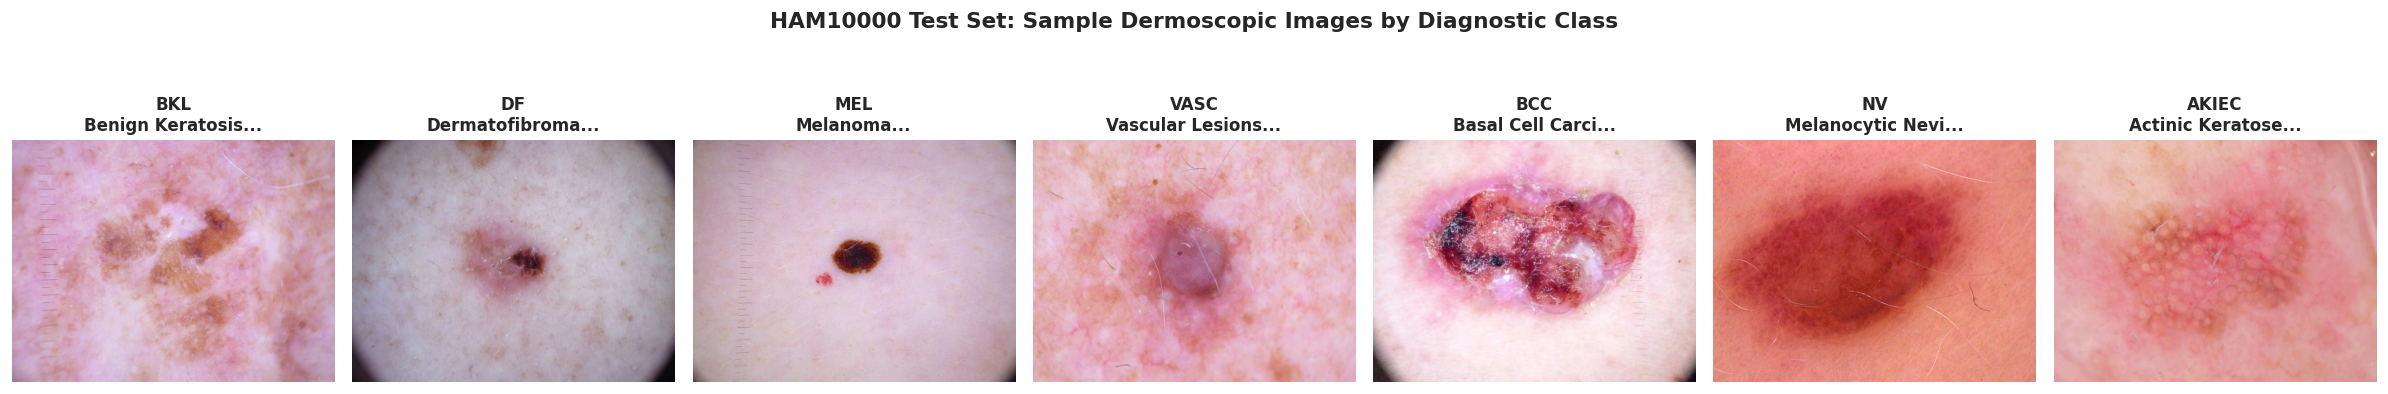

In [4]:
# 4. Visualizing Test Dataset Samples
# Inspect representative dermoscopic images for each of the 7 diagnostic classes
class_descriptions = {
    'akiec': 'Actinic Keratoses / Intraepithelial Carcinoma',
    'bcc': 'Basal Cell Carcinoma',
    'bkl': 'Benign Keratosis-like Lesions',
    'df': 'Dermatofibroma',
    'mel': 'Melanoma',
    'nv': 'Melanocytic Nevi',
    'vasc': 'Vascular Lesions'
}

fig, axes = plt.subplots(1, 7, figsize=(20, 3.5))
seen_classes = set()

# Find one sample per class from test set
for idx in test_indices:
    row = full_dataset.data.iloc[idx]
    dx = row['dx']
    if dx not in seen_classes:
        ax = axes[len(seen_classes)]
        img_path = full_dataset.image_paths[row['image_id']]
        raw_img = Image.open(img_path)
        ax.imshow(raw_img)
        ax.set_title(f"{dx.upper()}\n{class_descriptions[dx][:16]}...", fontsize=10, fontweight='bold')
        ax.axis("off")
        seen_classes.add(dx)
    if len(seen_classes) == 7:
        break

plt.suptitle("HAM10000 Test Set: Sample Dermoscopic Images by Diagnostic Class", fontsize=13, y=1.05, fontweight='bold')
plt.tight_layout()
plt.show()


In [5]:
# 5. Load Fine-Tuned ResNet-18 Checkpoint
model = build_model(num_classes=NUM_CLASSES, model_name="resnet18")
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
model.load_state_dict(checkpoint)
model.to(device)
model.eval()

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
file_size_mb = os.path.getsize(CHECKPOINT_PATH) / (1024 * 1024)

print(f"Model Architecture : ResNet-18 (Transfer Learned Head for {NUM_CLASSES} classes)")
print(f"Total Parameters   : {total_params:,}")
print(f"Trainable Params   : {trainable_params:,}")
print(f"Checkpoint File    : {CHECKPOINT_PATH} ({file_size_mb:.2f} MB)")


Model Architecture : ResNet-18 (Transfer Learned Head for 7 classes)
Total Parameters   : 11,180,103
Trainable Params   : 11,180,103
Checkpoint File    : best_model.pth (42.72 MB)


In [6]:
# 6. Run Test Inference
all_labels = []
all_preds = []
all_probs = []

print("Running inference across the held-out test split...")
t_start = time.time()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        logits = model(images)
        probs = F.softmax(logits, dim=1).cpu().numpy()
        preds = logits.argmax(dim=1).cpu().tolist()
        
        all_labels.extend(labels.tolist())
        all_preds.extend(preds)
        all_probs.append(probs)

elapsed = time.time() - t_start
y_true = np.array(all_labels)
y_pred = np.array(all_preds)
y_prob = np.concatenate(all_probs, axis=0)

print(f"Inference completed in {elapsed:.2f} seconds ({len(y_true) / elapsed:.1f} img/s).")


Running inference across the held-out test split...


Inference completed in 21.37 seconds (48.4 img/s).


In [7]:
# 7. Performance Evaluation: Comprehensive Metrics
acc = accuracy_score(y_true, y_pred)

# Specificity (One-vs-Rest) calculation
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
specificities = []
for i in range(NUM_CLASSES):
    tp = cm[i, i]
    fn = cm[i, :].sum() - tp
    fp = cm[:, i].sum() - tp
    tn = cm.sum() - tp - fn - fp
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    specificities.append(spec)

# Per-class ROC-AUC (One-vs-Rest)
y_bin = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
aucs = []
for i in range(NUM_CLASSES):
    try:
        aucs.append(roc_auc_score(y_bin[:, i], y_prob[:, i]))
    except ValueError:
        aucs.append(np.nan)

# Precision, Recall, F1
prec_per = precision_score(y_true, y_pred, average=None, zero_division=0)
rec_per = recall_score(y_true, y_pred, average=None, zero_division=0)
f1_per = f1_score(y_true, y_pred, average=None, zero_division=0)
supports = [(y_true == i).sum() for i in range(NUM_CLASSES)]

# Per-class DataFrame
df_per_class = pd.DataFrame({
    "Class": class_names,
    "Diagnosis": [class_descriptions[c] for c in class_names],
    "Support": supports,
    "Precision": np.round(prec_per, 4),
    "Recall (Sensitivity)": np.round(rec_per, 4),
    "Specificity (OvR)": np.round(specificities, 4),
    "F1-Score": np.round(f1_per, 4),
    "ROC-AUC (OvR)": np.round(aucs, 4),
})

# Aggregates
macro_metrics = {
    "Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
    "Recall (Sensitivity)": recall_score(y_true, y_pred, average="macro", zero_division=0),
    "Specificity (OvR)": np.mean(specificities),
    "F1-Score": f1_score(y_true, y_pred, average="macro", zero_division=0),
    "ROC-AUC (OvR)": roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro"),
}

weighted_metrics = {
    "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
    "Recall (Sensitivity)": recall_score(y_true, y_pred, average="weighted", zero_division=0),
    "Specificity (OvR)": np.average(specificities, weights=supports),
    "F1-Score": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    "ROC-AUC (OvR)": roc_auc_score(y_true, y_prob, multi_class="ovr", average="weighted"),
}

df_summary = pd.DataFrame([
    {"Metric": "Accuracy", "Value": f"{acc:.4f} ({acc*100:.2f}%)"},
    {"Metric": "Macro Precision", "Value": f"{macro_metrics['Precision']:.4f}"},
    {"Metric": "Macro Recall", "Value": f"{macro_metrics['Recall (Sensitivity)']:.4f}"},
    {"Metric": "Macro Specificity", "Value": f"{macro_metrics['Specificity (OvR)']:.4f}"},
    {"Metric": "Macro F1-Score", "Value": f"{macro_metrics['F1-Score']:.4f}"},
    {"Metric": "Macro ROC-AUC", "Value": f"{macro_metrics['ROC-AUC (OvR)']:.4f}"},
    {"Metric": "Weighted Precision", "Value": f"{weighted_metrics['Precision']:.4f}"},
    {"Metric": "Weighted Recall", "Value": f"{weighted_metrics['Recall (Sensitivity)']:.4f}"},
    {"Metric": "Weighted Specificity", "Value": f"{weighted_metrics['Specificity (OvR)']:.4f}"},
    {"Metric": "Weighted F1-Score", "Value": f"{weighted_metrics['F1-Score']:.4f}"},
    {"Metric": "Weighted ROC-AUC", "Value": f"{weighted_metrics['ROC-AUC (OvR)']:.4f}"},
])

print("=== OVERALL METRICS SUMMARY ===")
print(df_summary.to_string(index=False))
print("\n=== PER-CLASS PERFORMANCE BREAKDOWN ===")
print(df_per_class.to_string(index=False))


=== OVERALL METRICS SUMMARY ===
              Metric           Value
            Accuracy 0.7903 (79.03%)
     Macro Precision          0.6480
        Macro Recall          0.6758
   Macro Specificity          0.9560
      Macro F1-Score          0.6536
       Macro ROC-AUC          0.9446
  Weighted Precision          0.8135
     Weighted Recall          0.7903
Weighted Specificity          0.9018
   Weighted F1-Score          0.7978
    Weighted ROC-AUC          0.9424

=== PER-CLASS PERFORMANCE BREAKDOWN ===
Class                                     Diagnosis  Support  Precision  Recall (Sensitivity)  Specificity (OvR)  F1-Score  ROC-AUC (OvR)
akiec Actinic Keratoses / Intraepithelial Carcinoma       35     0.5526                0.6000             0.9830    0.5753         0.9247
  bcc                          Basal Cell Carcinoma       75     0.7297                0.7200             0.9792    0.7248         0.9718
  bkl                 Benign Keratosis-like Lesions      129     0.72

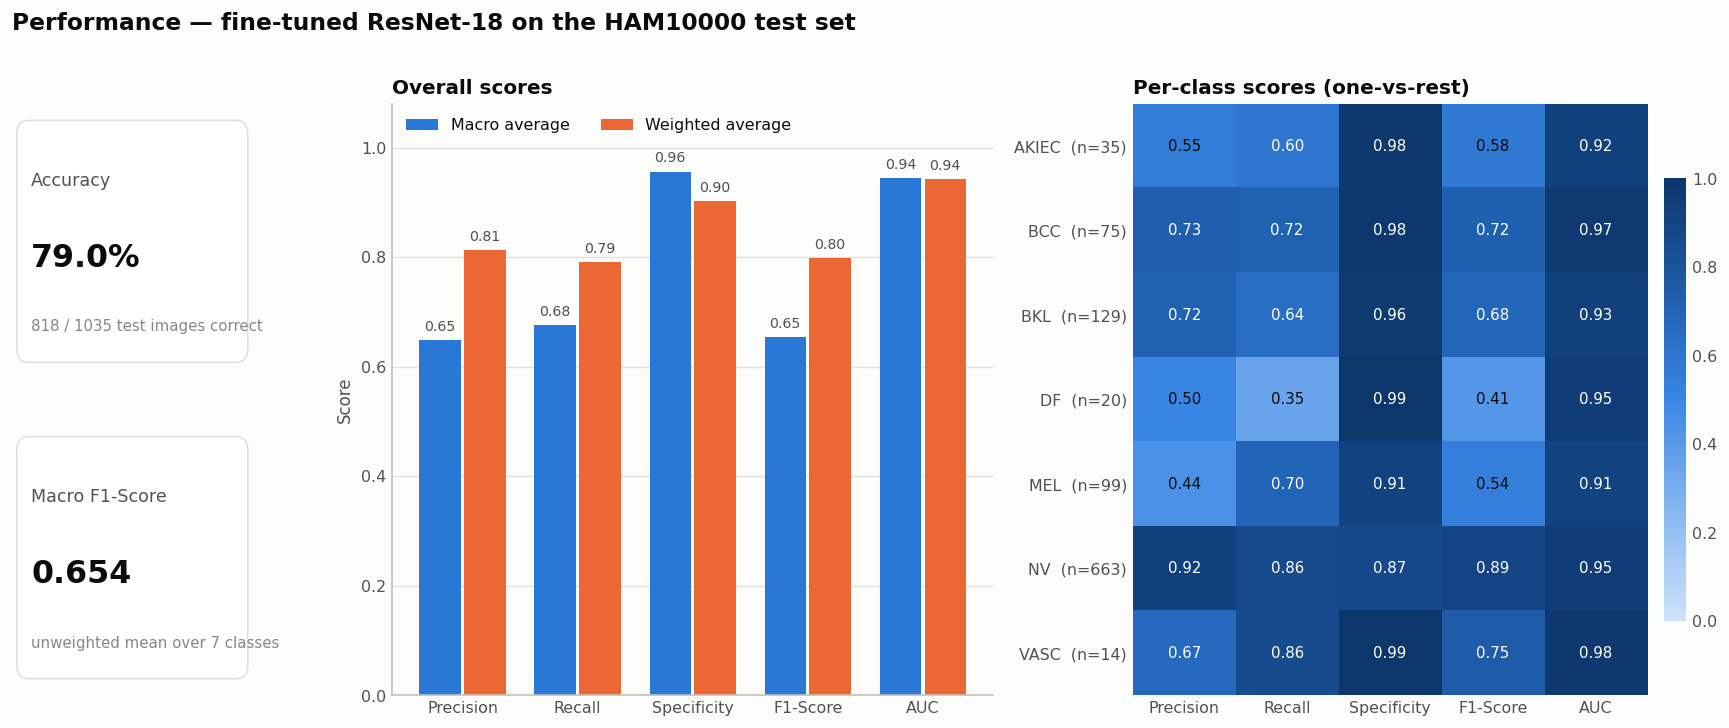

In [8]:
# 8. Performance family: Accuracy, Precision, Recall, Specificity, F1-Score, AUC
perf_metrics = ["Precision", "Recall (Sensitivity)", "Specificity (OvR)", "F1-Score", "ROC-AUC (OvR)"]
perf_short = ["Precision", "Recall", "Specificity", "F1-Score", "AUC"]

with plt.rc_context(FAMILY_RC):
    fig = plt.figure(figsize=(18, 6.4))
    gs = fig.add_gridspec(2, 3, width_ratios=[1, 2.5, 2.3], wspace=0.3, hspace=0.15)

    stat_tile(fig.add_subplot(gs[0, 0]), f"{acc * 100:.1f}%", "Accuracy",
              f"{int((y_true == y_pred).sum())} / {len(y_true)} test images correct")
    stat_tile(fig.add_subplot(gs[1, 0]), f"{macro_metrics['F1-Score']:.3f}", "Macro F1-Score",
              "unweighted mean over 7 classes")

    # Overall scores: macro (every class counts equally) vs weighted (by class support)
    ax = fig.add_subplot(gs[:, 1])
    x = np.arange(len(perf_metrics))
    width = 0.36
    for k, (name, values) in enumerate([("Macro average", macro_metrics), ("Weighted average", weighted_metrics)]):
        heights = [values[m] for m in perf_metrics]
        bars = ax.bar(x + (k - 0.5) * (width + 0.03), heights, width, color=SERIES[k], label=name)
        for bar, h in zip(bars, heights):
            ax.text(bar.get_x() + bar.get_width() / 2, h + 0.012, f"{h:.2f}",
                    ha="center", va="bottom", fontsize=8.5, color=INK_2)
    ax.set_xticks(x)
    ax.set_xticklabels(perf_short)
    ax.set_ylim(0, 1.08)
    ax.set_ylabel("Score")
    ax.set_title("Overall scores", loc="left")
    ax.legend(loc="upper left", ncol=2, bbox_to_anchor=(0, 1.0))
    style_axes(ax)

    # Per-class breakdown: one row per lesion class, one column per metric
    ax = fig.add_subplot(gs[:, 2])
    grid = df_per_class[perf_metrics].to_numpy(dtype=float)
    im = ax.imshow(grid, cmap=SEQ_CMAP, vmin=0, vmax=1, aspect="auto")
    for (r, c), v in np.ndenumerate(grid):
        ax.text(c, r, "–" if np.isnan(v) else f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="#ffffff" if v >= 0.6 else INK)
    ax.set_xticks(range(len(perf_short)))
    ax.set_xticklabels(perf_short)
    ax.set_yticks(range(NUM_CLASSES))
    ax.set_yticklabels([f"{c.upper()}  (n={s})" for c, s in zip(class_names, supports)])
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title("Per-class scores (one-vs-rest)", loc="left")
    cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.03)
    cbar.outline.set_visible(False)
    cbar.ax.tick_params(length=0, colors=INK_2)

    fig.suptitle("Performance — fine-tuned ResNet-18 on the HAM10000 test set",
                 x=0.125, ha="left", fontsize=14, fontweight="bold", y=1.0)
    plt.show()

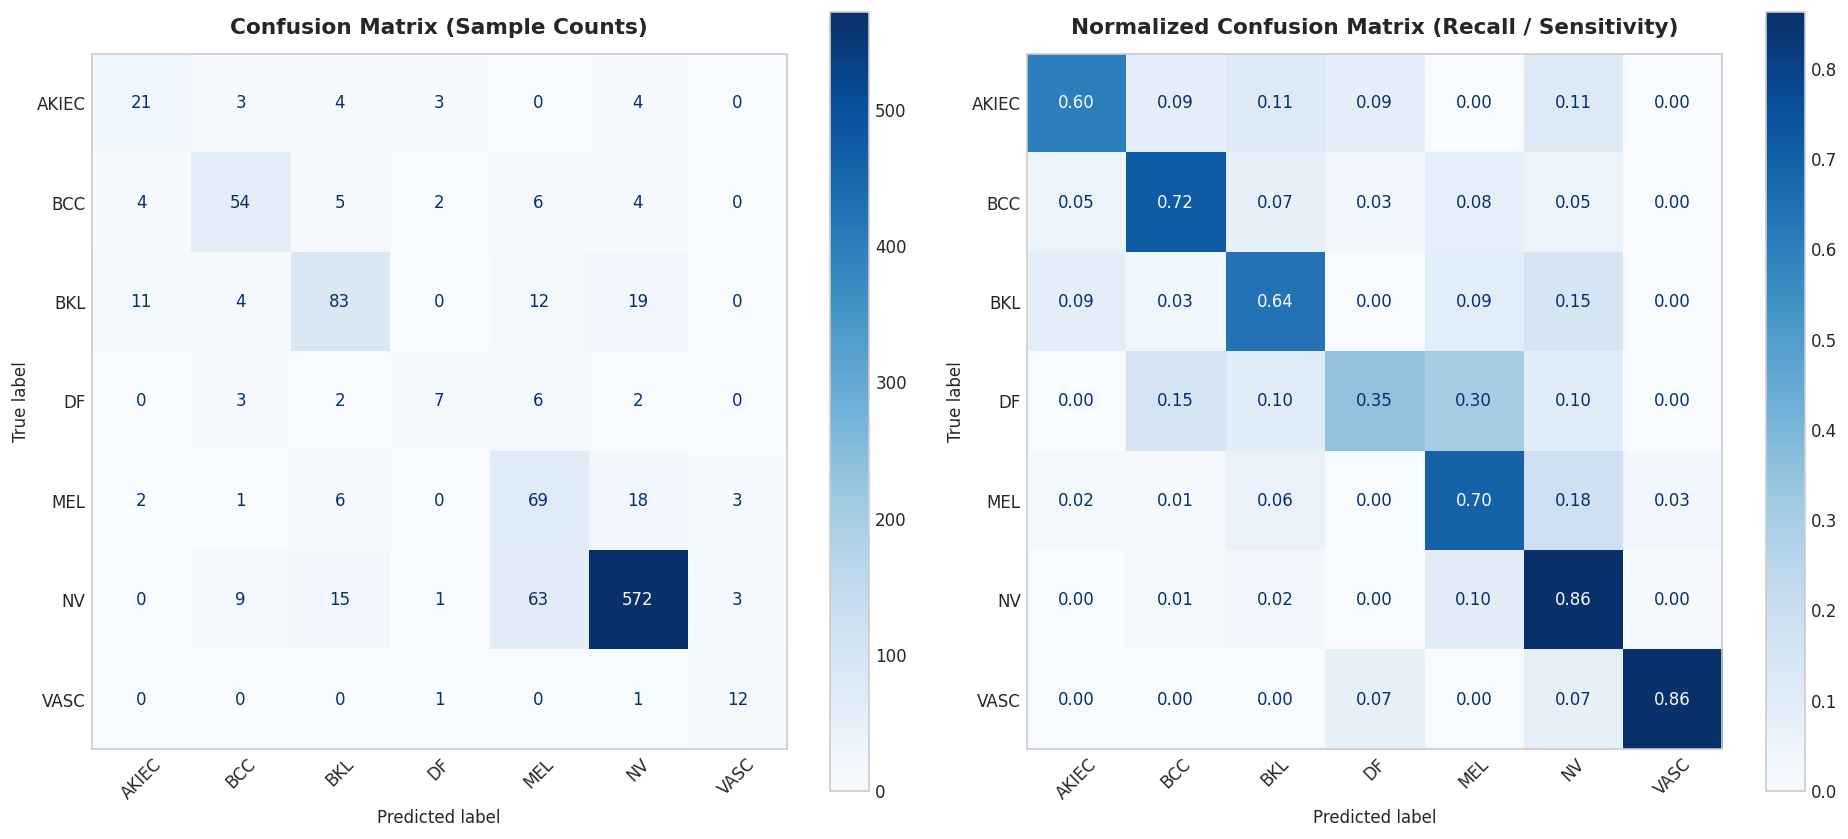

In [9]:
# 9. Confusion Matrices (Raw Counts & Row-Normalized)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 1. Unnormalized Confusion Matrix
disp_raw = ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred,
    display_labels=[c.upper() for c in class_names],
    xticks_rotation=45,
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Confusion Matrix (Sample Counts)", fontsize=13, fontweight='bold', pad=12)
axes[0].grid(False)

# 2. Normalized Confusion Matrix (Recall per class)
disp_norm = ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred,
    display_labels=[c.upper() for c in class_names],
    xticks_rotation=45,
    normalize="true",
    cmap="Blues",
    values_format=".2f",
    ax=axes[1]
)
axes[1].set_title("Normalized Confusion Matrix (Recall / Sensitivity)", fontsize=13, fontweight='bold', pad=12)
axes[1].grid(False)

plt.tight_layout()
plt.show()


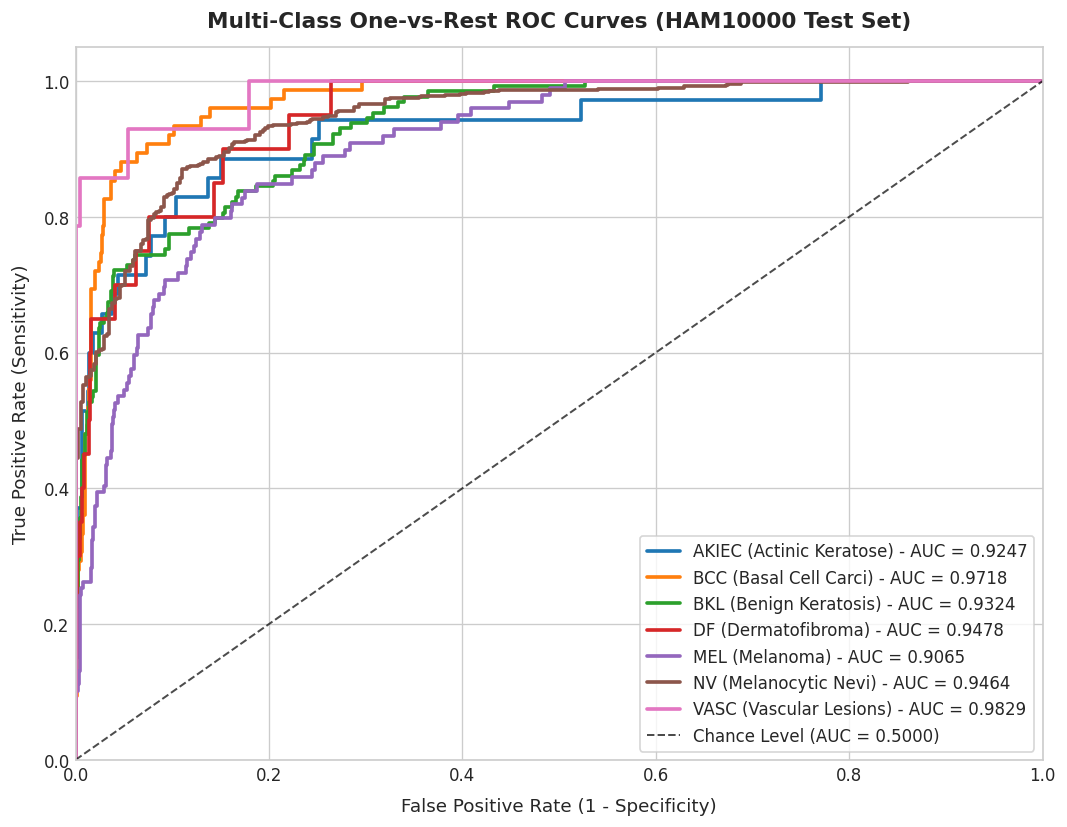

In [10]:
# 10. One-vs-Rest ROC Curves for All 7 Classes
fig, ax = plt.subplots(figsize=(9, 7))

colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2"]

for i, (name, color) in enumerate(zip(class_names, colors)):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
    class_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=color, lw=2.2, label=f"{name.upper()} ({class_descriptions[name][:16]}) - AUC = {class_auc:.4f}")

# Diagonal reference line
ax.plot([0, 1], [0, 1], "k--", lw=1.2, alpha=0.7, label="Chance Level (AUC = 0.5000)")
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11, labelpad=8)
ax.set_ylabel("True Positive Rate (Sensitivity)", fontsize=11, labelpad=8)
ax.set_title("Multi-Class One-vs-Rest ROC Curves (HAM10000 Test Set)", fontsize=13, fontweight='bold', pad=12)
ax.legend(loc="lower right", frameon=True, fontsize=10)
plt.tight_layout()
plt.show()


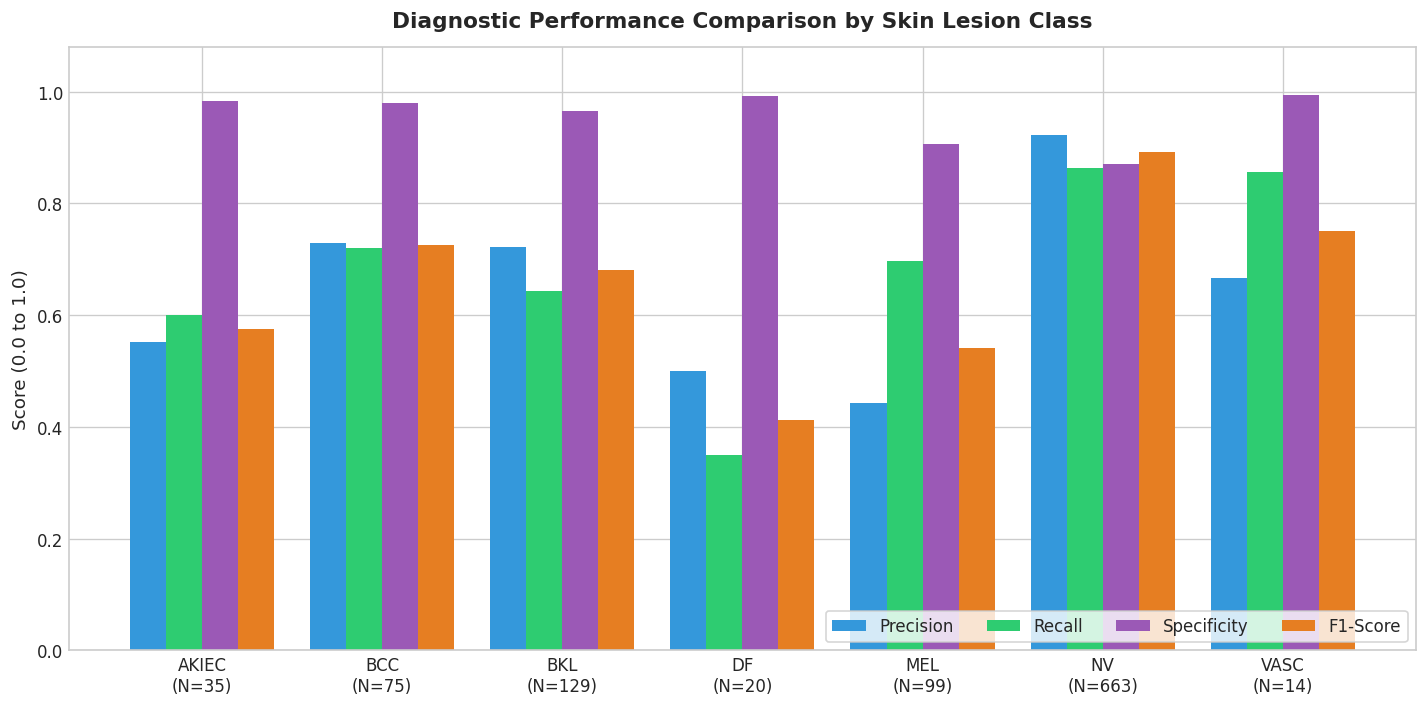

In [11]:
# 11. Per-Class Diagnostic Profile Comparison
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(class_names))
width = 0.2

rects1 = ax.bar(x - 1.5*width, df_per_class["Precision"], width, label="Precision", color="#3498db")
rects2 = ax.bar(x - 0.5*width, df_per_class["Recall (Sensitivity)"], width, label="Recall", color="#2ecc71")
rects3 = ax.bar(x + 0.5*width, df_per_class["Specificity (OvR)"], width, label="Specificity", color="#9b59b6")
rects4 = ax.bar(x + 1.5*width, df_per_class["F1-Score"], width, label="F1-Score", color="#e67e22")

ax.set_ylabel("Score (0.0 to 1.0)", fontsize=11)
ax.set_title("Diagnostic Performance Comparison by Skin Lesion Class", fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels([f"{c.upper()}\n(N={s})" for c, s in zip(class_names, supports)], fontsize=10)
ax.set_ylim([0.0, 1.08])
ax.legend(loc="lower right", frameon=True, ncol=4)
plt.tight_layout()
plt.show()


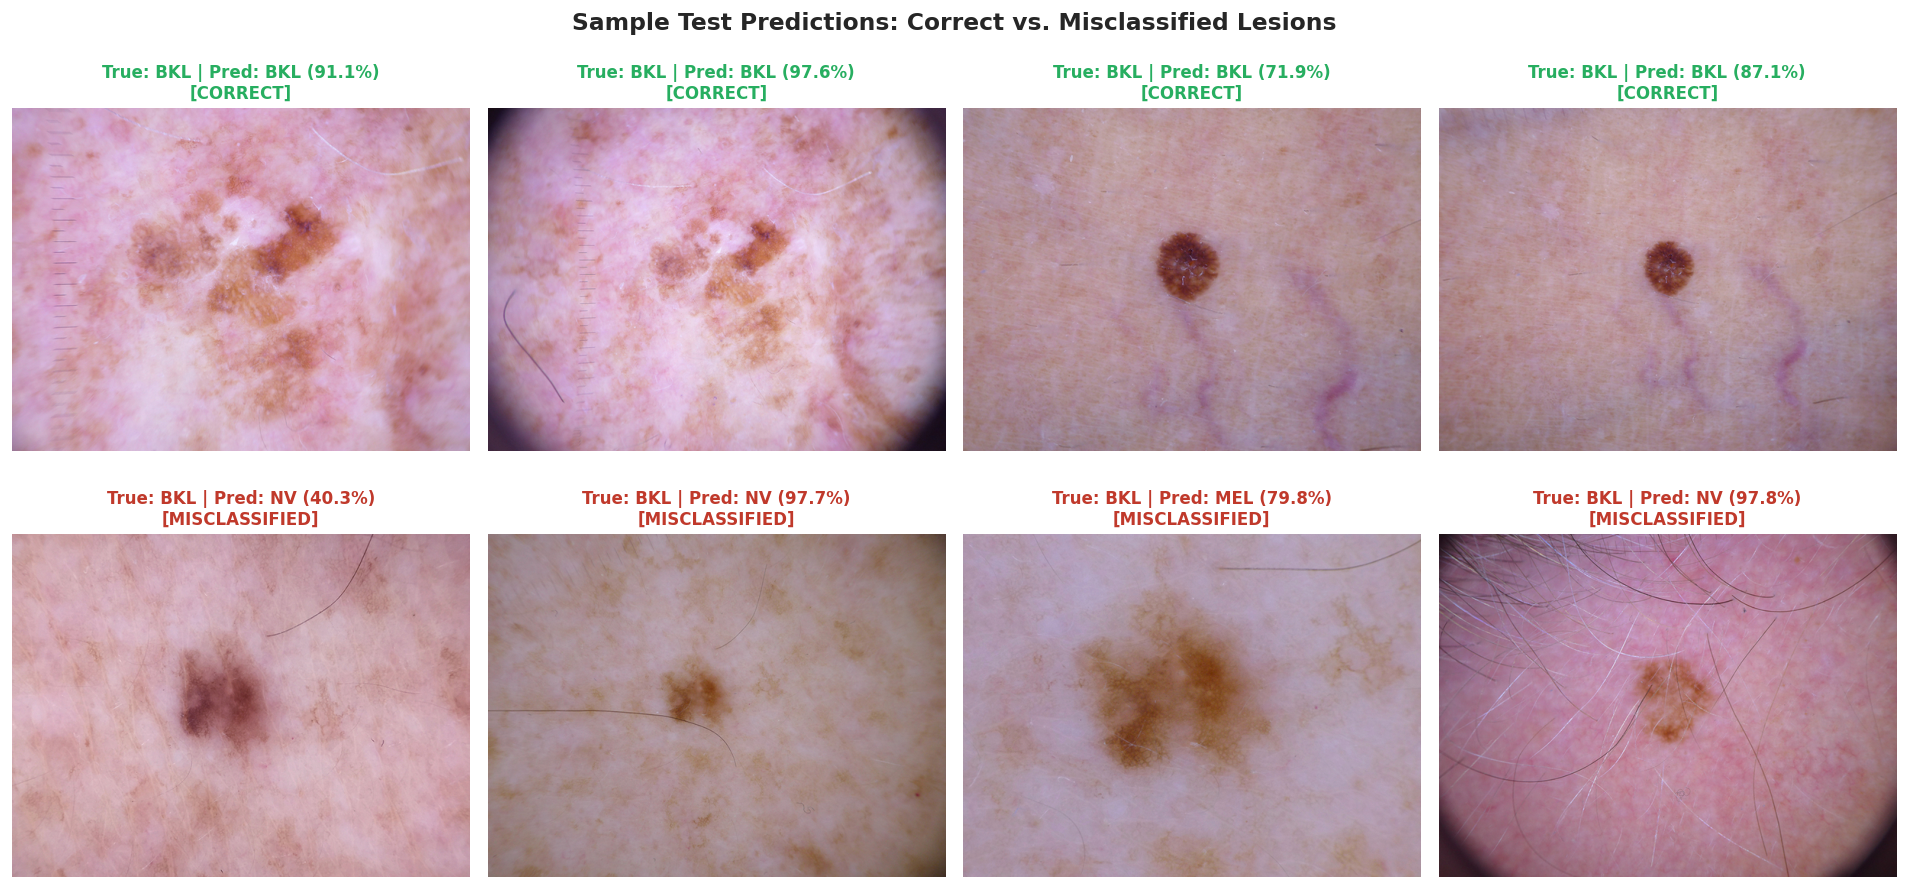

In [12]:
# 12. Sample Test Predictions Visualizer (Correct & Misclassified)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

# Pick 4 correct and 4 incorrect samples
correct_indices = np.where(y_true == y_pred)[0]
incorrect_indices = np.where(y_true != y_pred)[0]

sample_idxs = list(correct_indices[:4]) + list(incorrect_indices[:4])

for i, s_idx in enumerate(sample_idxs):
    ax = axes[i]
    dataset_idx = test_indices[s_idx]
    row = full_dataset.data.iloc[dataset_idx]
    img_path = full_dataset.image_paths[row['image_id']]
    img = Image.open(img_path)
    
    true_label = class_names[y_true[s_idx]].upper()
    pred_label = class_names[y_pred[s_idx]].upper()
    prob = y_prob[s_idx][y_pred[s_idx]] * 100
    is_correct = (y_true[s_idx] == y_pred[s_idx])
    
    status_color = "#27ae60" if is_correct else "#c0392b"
    status_text = "CORRECT" if is_correct else "MISCLASSIFIED"
    
    ax.imshow(img)
    ax.set_title(f"True: {true_label} | Pred: {pred_label} ({prob:.1f}%)\n[{status_text}]",
                 fontsize=10, fontweight='bold', color=status_color)
    ax.axis("off")

plt.suptitle("Sample Test Predictions: Correct vs. Misclassified Lesions", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


In [13]:
# 13. Computational Efficiency Benchmarking
from torch.profiler import profile, ProfilerActivity

use_cuda = (device.type == "cuda")

def sync():
    if use_cuda:
        torch.cuda.synchronize()

def time_forward(batch_size, runs, warmup):
    """Wall-clock time (ms) of one forward pass, per run."""
    x = torch.randn(batch_size, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
    for _ in range(warmup):
        model(x)
    sync()
    times = []
    for _ in range(runs):
        t0 = time.perf_counter()
        model(x)
        sync()
        times.append((time.perf_counter() - t0) * 1000)
    return np.array(times)

def peak_activation_mb(batch_size):
    """Peak memory the forward pass allocates on top of the weights and the input."""
    x = torch.randn(batch_size, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
    if use_cuda:
        torch.cuda.reset_peak_memory_stats(device)
        base = torch.cuda.memory_allocated(device)
        model(x)
        sync()
        return (torch.cuda.max_memory_allocated(device) - base) / 2**20
    # tracemalloc cannot see PyTorch's allocator, so replay the profiler's allocation events instead
    with profile(activities=[ProfilerActivity.CPU], profile_memory=True) as prof:
        model(x)
    events = sorted((e.time_range.start, e.self_cpu_memory_usage) for e in prof.events() if e.self_cpu_memory_usage)
    return max(0.0, float(np.cumsum([b for _, b in events]).max())) / 2**20

# 1. Size & FLOPs (ptflops counts multiply-accumulates; 1 MAC = 2 FLOPs)
weights_mb = sum(t.numel() * t.element_size() for t in [*model.parameters(), *model.buffers()]) / 2**20
macs, _ = get_model_complexity_info(
    model, (3, IMAGE_SIZE, IMAGE_SIZE),
    as_strings=False, print_per_layer_stat=False, verbose=False
)
flops_count = int(macs * 2)

# 2. Latency, throughput and peak memory across batch sizes (inference mode: no autograd graph)
BATCH_SIZES = [1, 8, 16, 32, 64]
RUNS = {1: 100, 8: 30, 16: 20, 32: 15, 64: 10}
sweep_rows = []
with torch.no_grad():
    for bs in BATCH_SIZES:
        times = time_forward(bs, runs=RUNS[bs], warmup=20 if bs == 1 else 3)
        if bs == 1:
            latency_times = times
        input_mb = bs * 3 * IMAGE_SIZE * IMAGE_SIZE * 4 / 2**20
        sweep_rows.append({
            "batch_size": bs,
            "latency_ms": float(times.mean()),
            "latency_std_ms": float(times.std()),
            "throughput_ips": bs * 1000 / float(times.mean()),
            "peak_memory_mb": weights_mb + input_mb + peak_activation_mb(bs),
        })
df_sweep = pd.DataFrame(sweep_rows)

mean_latency = float(latency_times.mean())
std_latency = float(latency_times.std())
throughput_ips = float(df_sweep.loc[df_sweep.batch_size == 32, "throughput_ips"].iloc[0])
peak_mem_mb = float(df_sweep.loc[df_sweep.batch_size == 1, "peak_memory_mb"].iloc[0])
mem_type = "GPU (CUDA allocator)" if use_cuda else "CPU (torch profiler)"

df_efficiency = pd.DataFrame([
    {"Metric": "Total Parameters", "Value": f"{total_params:,}"},
    {"Metric": "Checkpoint Size", "Value": f"{file_size_mb:.2f} MB"},
    {"Metric": "Weights in Memory", "Value": f"{weights_mb:.2f} MB"},
    {"Metric": "Computational Cost (FLOPs)", "Value": f"{flops_count:,} ({flops_count/1e9:.2f} GFLOPs)"},
    {"Metric": "Inference Latency (bs=1)", "Value": f"{mean_latency:.2f} ± {std_latency:.2f} ms / image"},
    {"Metric": "Throughput (bs=32)", "Value": f"{throughput_ips:.1f} images/sec"},
    {"Metric": "Peak Memory (bs=1)", "Value": f"{peak_mem_mb:.2f} MB ({mem_type})"},
])

print("=== COMPUTATIONAL EFFICIENCY SUMMARY ===")
print(df_efficiency.to_string(index=False))
print("\n=== BATCH-SIZE SWEEP ===")
print(df_sweep.round(2).to_string(index=False))

=== COMPUTATIONAL EFFICIENCY SUMMARY ===
                    Metric                           Value
          Total Parameters                      11,180,103
           Checkpoint Size                        42.72 MB
         Weights in Memory                        42.69 MB
Computational Cost (FLOPs)     3,649,608,718 (3.65 GFLOPs)
  Inference Latency (bs=1)          4.03 ± 0.33 ms / image
        Throughput (bs=32)                694.3 images/sec
        Peak Memory (bs=1) 68.74 MB (GPU (CUDA allocator))

=== BATCH-SIZE SWEEP ===
 batch_size  latency_ms  latency_std_ms  throughput_ips  peak_memory_mb
          1        4.03            0.33          248.37           68.74
          8       16.40            0.56          487.76           96.28
         16       23.61            0.64          677.72          156.56
         32       46.09            0.82          694.33          269.87
         64       88.16            1.09          725.91          497.44


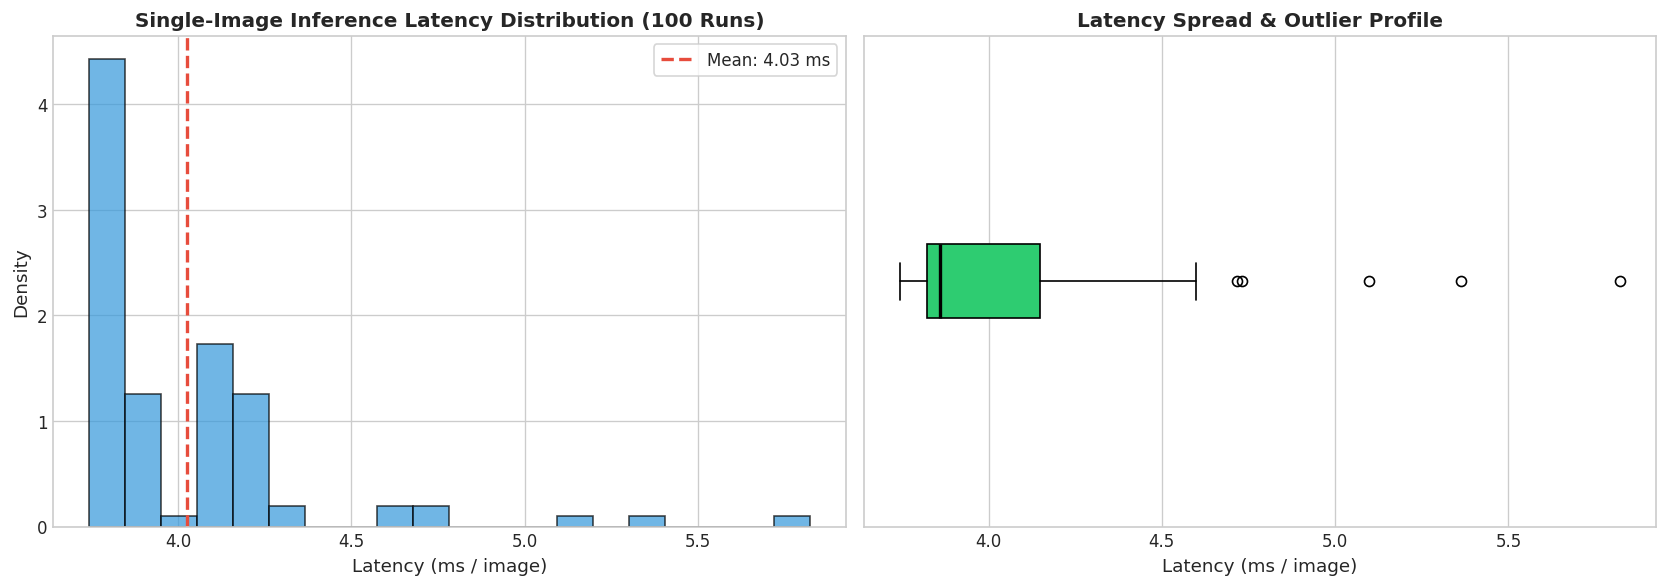

In [14]:
# 14. Latency Distribution Analysis
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Histogram + KDE
ax1.hist(latency_times, bins=20, color="#3498db", edgecolor="black", alpha=0.7, density=True)
ax1.axvline(mean_latency, color="#e74c3c", linestyle="--", lw=2, label=f"Mean: {mean_latency:.2f} ms")
ax1.set_xlabel("Latency (ms / image)", fontsize=11)
ax1.set_ylabel("Density", fontsize=11)
ax1.set_title("Single-Image Inference Latency Distribution (100 Runs)", fontsize=12, fontweight='bold')
ax1.legend(loc="upper right", frameon=True)

# Boxplot
ax2.boxplot(latency_times, vert=False, patch_artist=True,
            boxprops=dict(facecolor="#2ecc71", color="black"),
            medianprops=dict(color="black", lw=2))
ax2.set_xlabel("Latency (ms / image)", fontsize=11)
ax2.set_yticks([])
ax2.set_title("Latency Spread & Outlier Profile", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


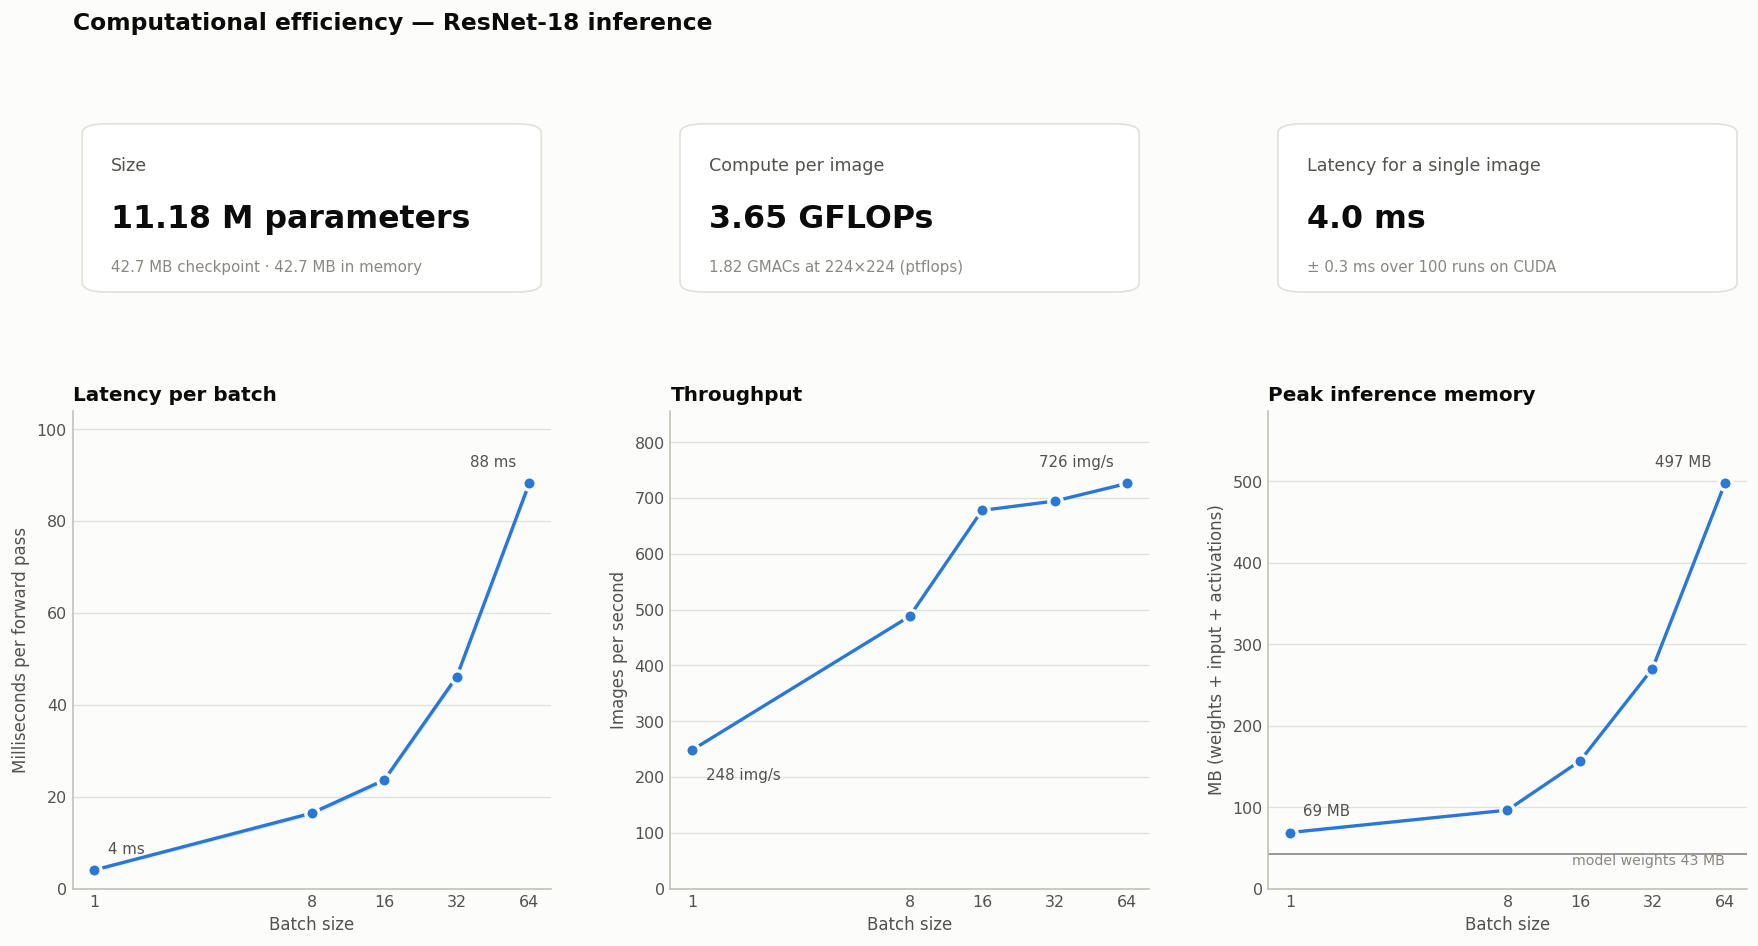

In [15]:
# 15. Efficiency family: Size, FLOPs, Latency, Throughput, Memory
with plt.rc_context(FAMILY_RC):
    fig = plt.figure(figsize=(18, 8.4))
    gs = fig.add_gridspec(2, 3, height_ratios=[1, 2.5], hspace=0.32, wspace=0.25)

    stat_tile(fig.add_subplot(gs[0, 0]), f"{total_params / 1e6:.2f} M parameters", "Size",
              f"{file_size_mb:.1f} MB checkpoint · {weights_mb:.1f} MB in memory")
    stat_tile(fig.add_subplot(gs[0, 1]), f"{flops_count / 1e9:.2f} GFLOPs", "Compute per image",
              f"{macs / 1e9:.2f} GMACs at {IMAGE_SIZE}×{IMAGE_SIZE} (ptflops)")
    stat_tile(fig.add_subplot(gs[0, 2]), f"{mean_latency:.1f} ms", "Latency for a single image",
              f"± {std_latency:.1f} ms over {len(latency_times)} runs on {device.type.upper()}")

    panels = [
        ("latency_ms", "Latency per batch", "Milliseconds per forward pass", "{:.0f} ms"),
        ("throughput_ips", "Throughput", "Images per second", "{:.0f} img/s"),
        ("peak_memory_mb", "Peak inference memory", "MB (weights + input + activations)", "{:.0f} MB"),
    ]
    for i, (col, title, ylabel, fmt) in enumerate(panels):
        ax = fig.add_subplot(gs[1, i])
        bs, y = df_sweep["batch_size"], df_sweep[col]
        if col == "latency_ms":
            ax.fill_between(bs, y - df_sweep["latency_std_ms"], y + df_sweep["latency_std_ms"],
                            color=SERIES[0], alpha=0.15, linewidth=0)
        if col == "peak_memory_mb":
            ax.axhline(weights_mb, color=MUTED, linewidth=1)
            ax.text(bs.iloc[-1], weights_mb, f"model weights {weights_mb:.0f} MB", color=MUTED,
                    fontsize=8.5, ha="right", va="top")
        ax.plot(bs, y, color=SERIES[0], linewidth=2, marker="o", markersize=8,
                markeredgecolor=SURFACE, markeredgewidth=2)
        # Label the two ends only, below the point when the line rises away from it there
        start_dy = -18 if y.iloc[0] > 0.3 * y.max() else 10
        end_dy = -18 if y.iloc[-2] > y.iloc[-1] else 10
        for j, ha, dx, dy in ((0, "left", 8, start_dy), (len(bs) - 1, "right", -8, end_dy)):
            ax.annotate(fmt.format(y.iloc[j]), (bs.iloc[j], y.iloc[j]), textcoords="offset points",
                        xytext=(dx, dy), ha=ha, fontsize=9, color=INK_2)
        ax.set_xscale("log", base=2)
        ax.set_xticks(BATCH_SIZES)
        ax.set_xticklabels([str(b) for b in BATCH_SIZES])
        ax.minorticks_off()
        ax.set_ylim(0, y.max() * 1.18)
        ax.set_xlabel("Batch size")
        ax.set_ylabel(ylabel)
        ax.set_title(title, loc="left")
        style_axes(ax)

    fig.suptitle("Computational efficiency — ResNet-18 inference",
                 x=0.125, ha="left", fontsize=14, fontweight="bold", y=0.98)
    plt.show()

In [16]:
# 16. Environmental Footprint Tracking (CodeCarbon)
tracker = EmissionsTracker(
    project_name="ham10000-eval-notebook",
    log_level="error",
    save_to_file=False,
)

print("Tracking real energy and carbon emissions during test inference...")
tracker.start()
with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(device)
        _ = model(images)
        if use_cuda:
            torch.cuda.synchronize()
emissions_kg = tracker.stop()

env_data = tracker.final_emissions_data
energy_kwh = env_data.energy_consumed
energy_by_component_kwh = {"CPU": env_data.cpu_energy, "RAM": env_data.ram_energy, "GPU": env_data.gpu_energy}
carbon_intensity = emissions_kg / energy_kwh * 1000 if energy_kwh else float("nan")  # g CO2e per kWh
avg_power_w = energy_kwh * 3.6e6 / env_data.duration

df_environment = pd.DataFrame([
    {"Metric": "Total Energy Consumed", "Value": f"{energy_kwh:.8f} kWh ({energy_kwh * 3.6e6:.2f} Joules)"},
    *[{"Metric": f"  {name} Energy", "Value": f"{kwh * 3.6e6:.2f} Joules"} for name, kwh in energy_by_component_kwh.items()],
    {"Metric": "Carbon Footprint (CO2e)", "Value": f"{emissions_kg:.8f} kg ({emissions_kg * 1000:.4f} g CO2e)"},
    {"Metric": "Energy Per Image", "Value": f"{(energy_kwh / len(test_subset)) * 1e6:.4f} mWh / image"},
    {"Metric": "Emissions Per Image", "Value": f"{(emissions_kg / len(test_subset)) * 1e6:.4f} mg CO2e / image"},
    {"Metric": "Average Power Draw", "Value": f"{avg_power_w:.1f} W over {env_data.duration:.1f} s"},
    {"Metric": "Grid Carbon Intensity", "Value": f"{carbon_intensity:.0f} g CO2e / kWh ({env_data.country_name})"},
    {"Metric": "Tracking Mechanism", "Value": "CodeCarbon EmissionsTracker (CPU & Hardware)"},
])

print("=== ENVIRONMENTAL IMPACT SUMMARY ===")
print(df_environment.to_string(index=False))

[codecarbon WARNING @ 10:04:12] Multiple instances of codecarbon are allowed to run at the same time.


Tracking real energy and carbon emissions during test inference...


=== ENVIRONMENTAL IMPACT SUMMARY ===
                 Metric                                        Value
  Total Energy Consumed               0.00021697 kWh (781.10 Joules)
             CPU Energy                                501.87 Joules
             RAM Energy                                105.67 Joules
             GPU Energy                                173.57 Joules
Carbon Footprint (CO2e)                0.00012236 kg (0.1224 g CO2e)
       Energy Per Image                           0.2096 mWh / image
    Emissions Per Image                       0.1182 mg CO2e / image
     Average Power Draw                           68.6 W over 11.4 s
  Grid Carbon Intensity                   564 g CO2e / kWh (Tunisia)
     Tracking Mechanism CodeCarbon EmissionsTracker (CPU & Hardware)


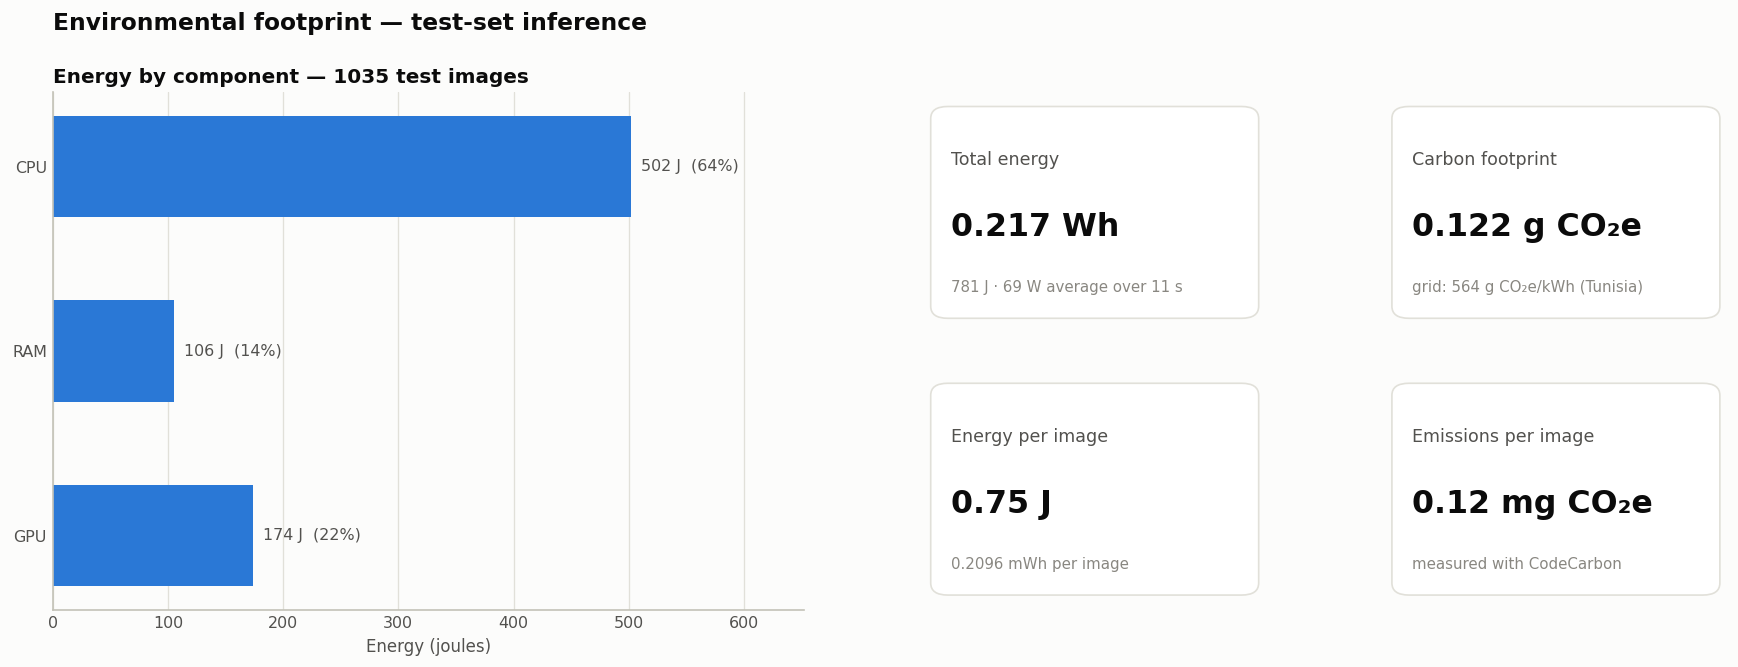

In [17]:
# 17. Environment family: Energy, CO2e
n_test = len(test_subset)
energy_j = energy_kwh * 3.6e6

with plt.rc_context(FAMILY_RC):
    fig = plt.figure(figsize=(18, 5.6))
    gs = fig.add_gridspec(2, 3, width_ratios=[2.2, 1, 1], wspace=0.25, hspace=0.15)

    # Where the energy went, by hardware component
    ax = fig.add_subplot(gs[:, 0])
    names = list(energy_by_component_kwh)
    joules = [energy_by_component_kwh[n] * 3.6e6 for n in names]
    bars = ax.barh(names, joules, height=0.55, color=SERIES[0])
    for bar, j in zip(bars, joules):
        share = j / energy_j * 100 if energy_j else 0
        ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f"  {j:.0f} J  ({share:.0f}%)",
                va="center", fontsize=9.5, color=INK_2)
    ax.invert_yaxis()
    ax.set_xlim(0, max(joules) * 1.3)
    ax.set_xlabel("Energy (joules)")
    ax.set_title(f"Energy by component — {n_test} test images", loc="left")
    style_axes(ax, grid_axis="x")

    stat_tile(fig.add_subplot(gs[0, 1]), f"{energy_kwh * 1000:.3f} Wh", "Total energy",
              f"{energy_j:.0f} J · {avg_power_w:.0f} W average over {env_data.duration:.0f} s")
    stat_tile(fig.add_subplot(gs[0, 2]), f"{emissions_kg * 1000:.3f} g CO₂e", "Carbon footprint",
              f"grid: {carbon_intensity:.0f} g CO₂e/kWh ({env_data.country_name})")
    stat_tile(fig.add_subplot(gs[1, 1]), f"{energy_j / n_test:.2f} J", "Energy per image",
              f"{energy_kwh / n_test * 1e6:.4f} mWh per image")
    stat_tile(fig.add_subplot(gs[1, 2]), f"{emissions_kg / n_test * 1e6:.2f} mg CO₂e", "Emissions per image",
              "measured with CodeCarbon")

    fig.suptitle("Environmental footprint — test-set inference",
                 x=0.125, ha="left", fontsize=14, fontweight="bold", y=1.0)
    plt.show()

In [18]:
# 18. Export Evaluation Results to results/metrics.json
results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)

metrics_payload = {
    "performance": {
        "accuracy": round(float(acc), 4),
        "macro": {k: round(float(v), 4) for k, v in macro_metrics.items()},
        "weighted": {k: round(float(v), 4) for k, v in weighted_metrics.items()},
        "per_class": df_per_class.set_index("Class").to_dict(orient="index")
    },
    "efficiency": {
        "model_size": {
            "total_params": total_params,
            "trainable_params": trainable_params,
            "file_size_mb": round(file_size_mb, 2)
        },
        "flops": {
            "flops": flops_count,
            "flops_method": "ptflops"
        },
        "latency": {
            "mean_ms": round(float(mean_latency), 3),
            "std_ms": round(float(std_latency), 3),
            "runs": len(latency_times)
        },
        "batch_sweep": df_sweep.round(3).to_dict(orient="records"),
        "throughput": {
            "images_per_sec": round(float(throughput_ips), 2),
            "batch_size": 32
        },
        "peak_memory": {
            "peak_memory_mb": round(float(peak_mem_mb), 2),
            "device_type": mem_type
        }
    },
    "environment": {
        "energy_kwh": round(float(energy_kwh), 8),
        "co2e_kg": round(float(emissions_kg), 8),
        "energy_by_component_kwh": {k: round(float(v), 8) for k, v in energy_by_component_kwh.items()},
        "carbon_intensity_g_per_kwh": round(float(carbon_intensity), 1),
        "duration_s": round(float(env_data.duration), 2)
    },
    "metadata": {
        "checkpoint": CHECKPOINT_PATH,
        "device": str(device),
        "split": "80 / 10 / 10 (lesion-wise, train / val / test)",
        "test_samples": len(test_subset),
    }
}

metrics_json_path = results_dir / "metrics.json"
with open(metrics_json_path, "w") as f:
    json.dump(metrics_payload, f, indent=2)

print(f"All metrics successfully verified and exported to: {metrics_json_path.resolve()}")


All metrics successfully verified and exported to: C:\Users\Speeker\OneDrive - SUPCOM\Desktop\FrugalAI\skin-lesion-classification\results\metrics.json
